# Fase 4 (extensión opcional) · LSTM

La guía propone como extensión opcional un segundo modelo para comparar: un **LSTM** (opción A) o la red PINN con SIR-SI del artículo (opción B). Aquí se hace la opción A, que es la más sencilla.

**Diseño, para que la comparación con el XGBoost del notebook 09 sea justa:**

| | XGBoost (notebook 09) | LSTM (este notebook) |
|---|---|---|
| Modelos | Uno por departamento y horizonte | **Uno global por horizonte**, entrenado con los 17 departamentos: una red necesita más datos que los ~600 de un departamento |
| Entrada | Casos de *T − h* a *T − h − 3*, estacionalidad y clima seleccionado | **Secuencia de las 12 semanas** que terminan en *T − h*: casos y (en la variante con clima) temperatura media, lluvia y humedad; más la estacionalidad de la semana objetivo y el departamento (*embedding*) |
| Objetivo | "delta" (casi siempre) | "delta": cambio de log1p(casos) respecto a *T − h* |
| Partición | Entrenamiento 2010–2021, validación 2022–2023 y prueba 2024 | Igual: parada temprana con validación y reentrenamiento con 2010–2023 por el mismo número de épocas |

Los casos se escalan con la media y la desviación de cada departamento en entrenamiento. El clima se escala con entrenamiento. La semilla es fija (42).

## Configuración

In [1]:
# Rutas: el notebook funciona desde la raiz del proyecto o desde notebooks/
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

from comun import ENTRENAMIENTO, HORIZONTES, PRUEBA, REGIONES, VALIDACION
from modelado import departamentos_modelables, metricas

PROC, OUT = ROOT / "data" / "processed", ROOT / "outputs"
SEMILLA = 42
VENTANA = 12                       # semanas de historia que ve el LSTM
CLIMA = ["temp_media", "precip_total", "hum_rel"]
OCULTAS, EMBEDDING = 32, 4
EPOCAS_MAX, PACIENCIA, LOTE, TASA = 80, 10, 128, 3e-3
torch.set_num_threads(4)
LSTM_SIN, LSTM_CON = "LSTM sin clima", "LSTM con clima"

## Datos y secuencias

In [3]:
panel = pd.read_parquet(PROC / "panel_depto_semana.parquet").sort_values(["departamento", "ano", "semana"])
deptos, _ = departamentos_modelables(panel)
panel = panel[panel["departamento"].isin(deptos)].reset_index(drop=True)
panel["log_casos"] = np.log1p(panel["casos"])
en_train = panel["ano"].between(*ENTRENAMIENTO)

# Escalado solo con entrenamiento: casos por departamento, clima global
stats = panel[en_train].groupby("departamento")["log_casos"].agg(["mean", "std"])
panel["casos_z"] = (panel["log_casos"] - panel["departamento"].map(stats["mean"])) / panel["departamento"].map(stats["std"]).clip(lower=1e-3)
for v in CLIMA:
    m, s = panel.loc[en_train, v].mean(), panel.loc[en_train, v].std()
    panel[f"{v}_z"] = (panel[v] - m) / s
indice_depto = {d: i for i, d in enumerate(deptos)}


def secuencias(h: int, con_clima: bool):
    """Una muestra por semana objetivo T: la ventana termina en T - h."""
    cols = ["casos_z"] + ([f"{v}_z" for v in CLIMA] if con_clima else [])
    X, E, S, Y, info = [], [], [], [], []
    for depto, d in panel.groupby("departamento", sort=False):
        valores = d[cols].to_numpy(dtype=np.float32)
        log_c = d["log_casos"].to_numpy()
        for t in range(VENTANA - 1 + h, len(d)):
            fin = t - h                               # ultima semana conocida
            X.append(valores[fin - VENTANA + 1: fin + 1])
            E.append(indice_depto[depto])
            sem = d["semana"].iat[t]
            S.append([np.sin(2 * np.pi * sem / 52), np.cos(2 * np.pi * sem / 52)])
            Y.append(log_c[t] - log_c[fin])           # objetivo "delta"
            info.append((depto, d["ano"].iat[t], sem, d["fecha"].iat[t], d["casos"].iat[t], log_c[fin]))
    info = pd.DataFrame(info, columns=["departamento", "ano", "semana", "fecha", "casos", "log_base"])
    return (torch.tensor(np.array(X)), torch.tensor(E), torch.tensor(np.array(S), dtype=torch.float32),
            torch.tensor(np.array(Y), dtype=torch.float32), info)


X, E, S, Y, info = secuencias(2, True)
print(f"Ejemplo h=2 con clima: {len(Y):,} muestras, ventana {tuple(X.shape[1:])}")

Ejemplo h=2 con clima: 13,073 muestras, ventana (12, 4)


## Modelo y entrenamiento

In [4]:
class LSTMDengue(nn.Module):
    def __init__(self, n_entradas: int, n_deptos: int):
        super().__init__()
        self.lstm = nn.LSTM(n_entradas, OCULTAS, batch_first=True)
        self.depto = nn.Embedding(n_deptos, EMBEDDING)
        self.salida = nn.Sequential(nn.Linear(OCULTAS + EMBEDDING + 2, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x, e, s):
        _, (h, _) = self.lstm(x)
        return self.salida(torch.cat([h[-1], self.depto(e), s], dim=1)).squeeze(1)


def entrenar(datos, mascara_tr, mascara_va=None, epocas=None):
    """Con mascara_va: parada temprana y devuelve el mejor numero de epocas. Sin ella: entrena 'epocas'."""
    torch.manual_seed(SEMILLA)
    np.random.seed(SEMILLA)
    X, E, S, Y = datos
    modelo = LSTMDengue(X.shape[2], len(deptos))
    opt = torch.optim.Adam(modelo.parameters(), lr=TASA)
    perdida = nn.MSELoss()
    idx_tr = np.flatnonzero(mascara_tr)
    mejor, mejor_ep, sin_mejora, estado = np.inf, 0, 0, None
    for ep in range(1, (epocas or EPOCAS_MAX) + 1):
        modelo.train()
        for lote in np.array_split(np.random.permutation(idx_tr), max(1, len(idx_tr) // LOTE)):
            opt.zero_grad()
            l = perdida(modelo(X[lote], E[lote], S[lote]), Y[lote])
            l.backward()
            opt.step()
        if mascara_va is not None:
            modelo.eval()
            with torch.no_grad():
                iv = np.flatnonzero(mascara_va)
                val = perdida(modelo(X[iv], E[iv], S[iv]), Y[iv]).item()
            if val < mejor - 1e-4:
                mejor, mejor_ep, sin_mejora = val, ep, 0
                estado = {k: v.clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejora += 1
                if sin_mejora >= PACIENCIA:
                    break
    if estado is not None:
        modelo.load_state_dict(estado)
    return modelo, mejor_ep


def predecir(modelo, datos, mascara, info):
    X, E, S, _ = datos
    i = np.flatnonzero(mascara)
    modelo.eval()
    with torch.no_grad():
        delta = modelo(X[i], E[i], S[i]).numpy()
    return np.clip(np.expm1(info["log_base"].to_numpy()[i] + delta), 0, None)


filas, preds = [], []
inicio = time.time()
for h in HORIZONTES:
    for nombre, con_clima in [(LSTM_SIN, False), (LSTM_CON, True)]:
        X, E, S, Y, info = secuencias(h, con_clima)
        datos = (X, E, S, Y)
        tr = info["ano"].between(*ENTRENAMIENTO).to_numpy()
        va = info["ano"].between(*VALIDACION).to_numpy()
        te = info["ano"].between(*PRUEBA).to_numpy()
        # 1) parada temprana con validacion
        modelo, epocas = entrenar(datos, tr, va)
        p_va = predecir(modelo, datos, va, info)
        # 2) reentrenar con entrenamiento + validacion por el mismo numero de epocas
        final, _ = entrenar(datos, tr | va, epocas=epocas)
        p_te = predecir(final, datos, te, info)
        for conjunto, mascara, p in [("Validacion", va, p_va), ("Prueba", te, p_te)]:
            sub = info[mascara].assign(prediccion=p)
            for depto, g in sub.groupby("departamento"):
                filas.append({"conjunto": conjunto, "departamento": depto, "horizonte": h, "modelo": nombre,
                              **metricas(g["casos"], g["prediccion"]), "epocas": epocas})
            preds.append(sub.assign(conjunto=conjunto, horizonte=h, modelo=nombre))
        print(f"  h={h} {nombre}: {epocas} epocas ({time.time() - inicio:,.0f} s)")

lstm = pd.DataFrame(filas)
pd.concat(preds, ignore_index=True).drop(columns="log_base").to_parquet(PROC / "predicciones_lstm.parquet", index=False)

  h=1 LSTM sin clima: 18 epocas (27 s)


  h=1 LSTM con clima: 11 epocas (49 s)


  h=2 LSTM sin clima: 7 epocas (64 s)


  h=2 LSTM con clima: 11 epocas (79 s)


  h=3 LSTM sin clima: 4 epocas (88 s)


  h=3 LSTM con clima: 7 epocas (100 s)


  h=4 LSTM sin clima: 3 epocas (107 s)


  h=4 LSTM con clima: 7 epocas (115 s)


## Comparación con XGBoost y las líneas base (mismas semanas)

In [5]:
xgb = pd.read_csv(OUT / "fase3_metricas.csv")
comparar = pd.concat([xgb[xgb["modelo"].isin(["Persistencia", "Regresion con rezagos", "XGBoost sin clima",
                                               "XGBoost con clima"])], lstm], ignore_index=True)
comparar.to_csv(OUT / "fase4_lstm_metricas.csv", index=False, float_format="%.4f")
orden = ["Persistencia", "Regresion con rezagos", "XGBoost sin clima", "XGBoost con clima", LSTM_SIN, LSTM_CON]

prueba = comparar[comparar["conjunto"] == "Prueba"]
print("Prueba 2024, R2 en las regiones principales:")
t = prueba[prueba["departamento"].isin(REGIONES)].pivot_table(index=["departamento", "modelo"], columns="horizonte", values="r2")
print(t.reindex([(d, m) for d in REGIONES for m in orden]).round(3).to_string())

mae = prueba.pivot_table(index=["departamento", "horizonte"], columns="modelo", values="mae")
print("\nPrueba 2024: departamentos (de 17) donde el LSTM tiene menor MAE que...")
for rival in ["Persistencia", "XGBoost sin clima", "XGBoost con clima"]:
    for lstm_nombre in [LSTM_SIN, LSTM_CON]:
        g = (mae[lstm_nombre] < mae[rival]).groupby(level="horizonte").sum()
        print(f"  {lstm_nombre} vs {rival}: " + ", ".join(f"h={h}: {g[h]}" for h in HORIZONTES))
g = (mae[LSTM_CON] < mae[LSTM_SIN]).groupby(level="horizonte").sum()
print("\n  LSTM con clima vs LSTM sin clima (H2 con otro modelo): " + ", ".join(f"h={h}: {g[h]}" for h in HORIZONTES))
print("\nMAE mediano entre departamentos (prueba 2024):")
print(prueba.pivot_table(index="modelo", columns="horizonte", values="mae", aggfunc="median").reindex(orden).round(1).to_string())

Prueba 2024, R2 en las regiones principales:
horizonte                               1      2      3      4
departamento modelo                                           
PIURA        Persistencia           0.939  0.846  0.708  0.519
             Regresion con rezagos  0.922  0.842  0.736  0.609
             XGBoost sin clima      0.933  0.775  0.639  0.378
             XGBoost con clima      0.923  0.868  0.764  0.533
             LSTM sin clima         0.921  0.872  0.678  0.768
             LSTM con clima         0.933  0.870  0.886  0.866
LORETO       Persistencia           0.832  0.657  0.432  0.262
             Regresion con rezagos  0.818  0.629  0.412  0.218
             XGBoost sin clima      0.852  0.725  0.538  0.419
             XGBoost con clima      0.784  0.740  0.435  0.365
             LSTM sin clima         0.842  0.700  0.485  0.338
             LSTM con clima         0.853  0.713  0.513  0.244
SAN MARTIN   Persistencia           0.879  0.815  0.649  0.512
          

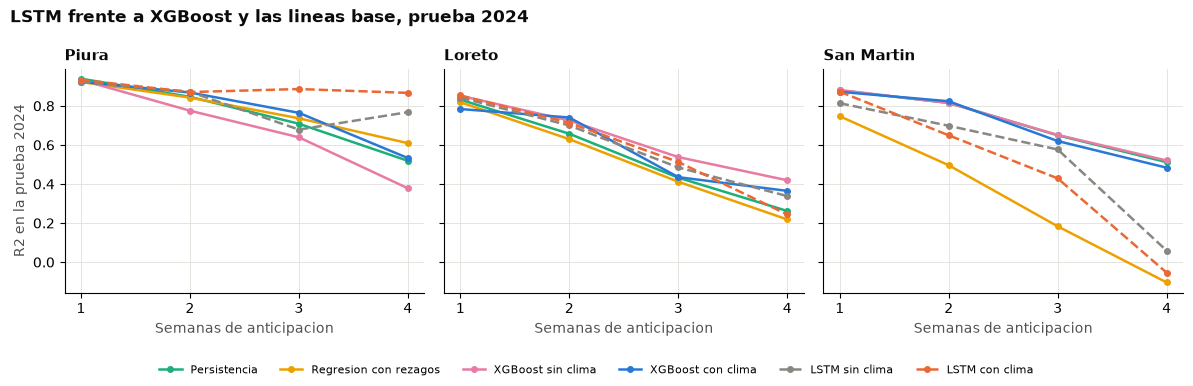

In [6]:
COLORES = {"Persistencia": "#1baf7a", "Regresion con rezagos": "#eda100", "XGBoost sin clima": "#e87ba4",
           "XGBoost con clima": "#2a78d6", LSTM_SIN: "#898781", LSTM_CON: "#eb6834"}
fig, ejes = plt.subplots(1, len(REGIONES), figsize=(12, 3.8), sharey=True)
for ax, depto in zip(ejes, REGIONES):
    for modelo in orden:
        s = prueba[(prueba["departamento"] == depto) & (prueba["modelo"] == modelo)].sort_values("horizonte")
        ax.plot(s["horizonte"], s["r2"], marker="o", ms=4, lw=1.8, color=COLORES[modelo], label=modelo,
                ls="--" if modelo.startswith("LSTM") else "-")
    ax.set_title(depto.title(), loc="left", fontsize=11, fontweight="bold", color="#0b0b0b")
    ax.set_xticks(HORIZONTES)
    ax.set_xlabel("Semanas de anticipacion", color="#52514e")
    ax.grid(color="#e1e0d9", lw=0.6)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
ejes[0].set_ylabel("R2 en la prueba 2024", color="#52514e")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=6, frameon=False, fontsize=8)
fig.suptitle("LSTM frente a XGBoost y las lineas base, prueba 2024", x=0.01, ha="left", fontsize=12,
             fontweight="bold", color="#0b0b0b")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(OUT / "fase4_lstm_comparacion.png", dpi=120)
plt.show()

## Resultados y conclusiones

El entrenamiento completo tarda unos 2 minutos. La parada temprana eligió entre 3 y 18 épocas.

**Error mediano entre los 17 departamentos** (MAE, prueba 2024, casos por semana):

| Modelo | 1 sem | 2 sem | 3 sem | 4 sem |
|---|---|---|---|---|
| Persistencia | 12,8 | 17,0 | 20,8 | 26,6 |
| XGBoost sin clima | 12,7 | 16,1 | 19,2 | 24,5 |
| XGBoost con clima | 12,9 | 15,3 | 20,2 | 25,2 |
| LSTM sin clima | 13,1 | 15,8 | 19,0 | 23,5 |
| **LSTM con clima** | **12,4** | **15,1** | **17,5** | **20,1** |

**Lectura:**
1. **El LSTM es competitivo con el XGBoost** y supera a la persistencia en 10 a 14 de 17 departamentos.
2. **El LSTM con clima tiene el menor error mediano y brilla en Piura** a 3–4 semanas (R² 0,89 y 0,87, frente a 0,76 y 0,53 del XGBoost con clima). Es el departamento con más casos y más historia, justo donde una red con 12 semanas de memoria le saca provecho al clima.
3. **Pero no es mejor en todas partes.** A 3–4 semanas le gana al XGBoost sin clima en solo 5–6 de 17 departamentos: es fuerte en los departamentos grandes y peor en varios pequeños. En San Martín es claramente peor.
4. **H2 con otro modelo:** el LSTM con clima mejora al LSTM sin clima en 7, 10, 6 y 6 de 17 departamentos (h = 1..4). Es el mismo resultado del notebook 11: **el clima no ayuda de forma consistente**, aunque sí en algunas regiones, como Piura.

**Precaución:** esto es **un solo año de prueba** (2024). El notebook 11 mostró que un solo corte puede llevar a conclusiones equivocadas. Antes de preferir el LSTM habría que evaluarlo con origen móvil (2016–2024), igual que al XGBoost. Además, con pocas épocas y 2 años de validación, el resultado depende de la semilla.

**Recomendación:** mantener el XGBoost sin clima como modelo de producción (validado en 9 años y en 2025 fuera de muestra) y presentar el LSTM con clima como una **línea prometedora para las regiones con mucha historia**, como Piura. El siguiente paso para confirmarlo sería validarlo con origen móvil.
